# 04: Interactive Unigram Surprisal Lab

## Objective

Investigate the behavior of Naive Monte Carlo
and Pathwise Marginalized Monte Carlo estimators
under different experimental configurations.

## Main questions

- How does sample size affect estimator variance?
- How does the number of bootstrap resamples
  affect the reported results?
- How sensitive are the results to the random seed?

In [1]:
import os
import sys
import json
import subprocess
import time

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets

from IPython.display import display, clear_output


PROJECT_ROOT = (
    Path.home()
    / "PROJECTS"
    / "unigram-surprisal-demo"
)

REPLAY_DIR = (
    PROJECT_ROOT / "data" / "variance_replay"
)

REPLAY_PYTHON = (
    PROJECT_ROOT / ".venv-replay" / "bin" / "python"
)

RESULTS_DIR = PROJECT_ROOT / "results"

NMC_COLOR = "#E69F00"
MMC_COLOR = "#009E73"

assert REPLAY_PYTHON.exists()
assert REPLAY_DIR.exists()

print("Replay environment:", REPLAY_PYTHON)
print("Verification data:", REPLAY_DIR)

Replay environment: /home/hydrogen/PROJECTS/unigram-surprisal-demo/.venv-replay/bin/python
Verification data: /home/hydrogen/PROJECTS/unigram-surprisal-demo/data/variance_replay


## Original Bootstrap Implementation

The interactive experiment calls the original
bootstrap_variance() function from the verification
archive.

In [2]:
EXPERIMENT_CODE = """
import sys
import json
import numpy as np

from author_code import variance

sample_size = int(sys.argv[1])
n_bootstrap = int(sys.argv[2])
seed = int(sys.argv[3])

inputs = variance.load_inputs("data")

nmc_variances = variance.bootstrap_variance(
    inputs.mc_counts,
    inputs.mc_boundaries - 1,
    sample_size,
    n_boot=n_bootstrap,
    rng=np.random.default_rng(seed),
)

mmc_variances = variance.bootstrap_variance(
    inputs.rb_prob_sums,
    inputs.rb_boundaries - 1,
    sample_size,
    n_boot=n_bootstrap,
    rng=np.random.default_rng(seed),
)

units = inputs.unit_index

nmc_unit_variances = nmc_variances[units]
mmc_unit_variances = mmc_variances[units]

common_mask = (
    np.isfinite(nmc_unit_variances)
    & np.isfinite(mmc_unit_variances)
)

nmc_mean = float(
    np.nanmean(nmc_variances[units])
)

mmc_mean = float(
    np.nanmean(mmc_variances[units])
)

result = {
    "sample_size": sample_size,
    "n_bootstrap": n_bootstrap,
    "seed": seed,
    "pool_size": inputs.n_samples,
    "nmc_variance": nmc_mean,
    "mmc_variance": mmc_mean,
    "nmc_defined_units": int(
        np.isfinite(nmc_variances[units]).sum()
    ),
    "mmc_defined_units": int(
        np.isfinite(mmc_variances[units]).sum()
    ),
    "total_units": len(units),
        "common_defined_units": int(
        common_mask.sum()
    ),
    "nmc_common_variance": float(
        np.mean(nmc_unit_variances[common_mask])
    ) if common_mask.any() else None,
    "mmc_common_variance": float(
        np.mean(mmc_unit_variances[common_mask])
    ) if common_mask.any() else None,
}

print(json.dumps(result))
"""

In [3]:
def run_variance_experiment(
    sample_size=100,
    n_bootstrap=1000,
    seed=0,
):
    env = os.environ.copy()

    env["OPENBLAS_NUM_THREADS"] = "1"
    env["OMP_NUM_THREADS"] = "1"

    start = time.perf_counter()

    process = subprocess.run(
        [
            str(REPLAY_PYTHON),
            "-B",
            "-c",
            EXPERIMENT_CODE,
            str(sample_size),
            str(n_bootstrap),
            str(seed),
        ],
        cwd=REPLAY_DIR,
        env=env,
        capture_output=True,
        text=True,
    )

    process.check_returncode()

    result = json.loads(process.stdout)

    result["execution_time"] = (
        time.perf_counter() - start
    )

    result["variance_ratio"] = (
        result["nmc_variance"]
        / result["mmc_variance"]
        if result["mmc_variance"] > 0
        else np.nan
    )

    result["warnings"] = process.stderr

    return result

In [4]:
result = run_variance_experiment(
    sample_size=100,
    n_bootstrap=1000,
    seed=0,
)

for key, value in result.items():
    if key in ("nmc_variance", "mmc_variance"):
        print(f"{key:25s}: {value:.8e}")
    else:
        print(f"{key:25s}: {value}")

sample_size              : 100
n_bootstrap              : 1000
seed                     : 0
pool_size                : 500
nmc_variance             : 2.18087481e-07
mmc_variance             : 2.00016771e-08
nmc_defined_units        : 551
mmc_defined_units        : 2107
total_units              : 2107
common_defined_units     : 551
nmc_common_variance      : 2.1808748138392264e-07
mmc_common_variance      : 7.583213336171567e-08
execution_time           : 0.540695952000533
variance_ratio           : 10.903459781090891
warnings                 : /home/hydrogen/PROJECTS/unigram-surprisal-demo/data/variance_replay/author_code/variance.py:174: RuntimeWarning: Degrees of freedom <= 0 for slice.
  return np.nanvar(estimates, axis=0, ddof=1)



In [5]:
sample_sizes = [100, 200, 300, 400, 500]

experiment_results = pd.DataFrame([
    run_variance_experiment(
        sample_size=j,
        n_bootstrap=1000,
        seed=0,
    )
    for j in sample_sizes
])

experiment_results[
    [
        "sample_size",
        "nmc_variance",
        "mmc_variance",
        "variance_ratio",
        "nmc_defined_units",
        "mmc_defined_units",
        "total_units",
        "execution_time",
    ]
]

,sample_size,nmc_variance,mmc_variance,variance_ratio,nmc_defined_units,mmc_defined_units,total_units,execution_time
0,100,2.180875e-07,2.000168e-08,10.903460,551,2107,2107,0.511621
1,200,1.154723e-07,9.199260e-09,12.552348,551,2107,2107,0.505706
2,300,8.193094e-08,6.596808e-09,12.419786,551,2107,2107,0.511361
3,400,6.424533e-08,4.955774e-09,12.963731,551,2107,2107,0.504245
4,500,5.056525e-08,3.885040e-09,13.015375,551,2107,2107,0.532437


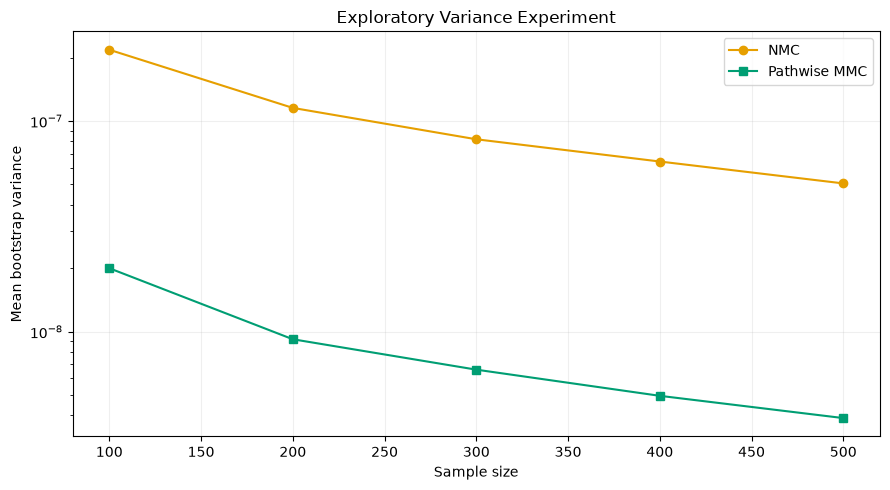

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    experiment_results["sample_size"],
    experiment_results["nmc_variance"],
    marker="o",
    color=NMC_COLOR,
    label="NMC",
)

ax.plot(
    experiment_results["sample_size"],
    experiment_results["mmc_variance"],
    marker="s",
    color=MMC_COLOR,
    label="Pathwise MMC",
)

ax.set_yscale("log")
ax.set_xlabel("Sample size")
ax.set_ylabel("Mean bootstrap variance")
ax.set_title("Exploratory Variance Experiment")

ax.legend()
ax.grid(alpha=0.2)

fig.tight_layout()

plt.show()

## Common-Support Variance Analysis

In [7]:
experiment_results["common_variance_ratio"] = (
    experiment_results["nmc_common_variance"]
    / experiment_results["mmc_common_variance"]
)

experiment_results["nmc_defined_coverage"] = (
    experiment_results["nmc_defined_units"]
    / experiment_results["total_units"]
)

experiment_results["mmc_defined_coverage"] = (
    experiment_results["mmc_defined_units"]
    / experiment_results["total_units"]
)

experiment_results[
    [
        "sample_size",
        "variance_ratio",
        "common_variance_ratio",
        "common_defined_units",
        "nmc_defined_coverage",
        "mmc_defined_coverage",
    ]
]

,sample_size,variance_ratio,common_variance_ratio,common_defined_units,nmc_defined_coverage,mmc_defined_coverage
0,100,10.903460,2.875924,551,0.261509,1.0
1,200,12.552348,3.314373,551,0.261509,1.0
2,300,12.419786,3.275823,551,0.261509,1.0
3,400,12.963731,3.418576,551,0.261509,1.0
4,500,13.015375,3.433282,551,0.261509,1.0


## Interactive Variance Explorer

The interface displays:

- Mean variance for both estimators
- Variance ratio
- Defined-variance coverage
- Common-support comparison
- Execution time

In [8]:
def visualize_experiment(result):
    nmc = result["nmc_variance"]
    mmc = result["mmc_variance"]

    summary = pd.DataFrame({
        "Estimator": ["NMC", "Pathwise MMC"],
        "Mean variance": [nmc, mmc],
        "Defined units": [
            result["nmc_defined_units"],
            result["mmc_defined_units"],
        ],
        "Coverage": [
            result["nmc_defined_units"]
            / result["total_units"],
            result["mmc_defined_units"]
            / result["total_units"],
        ],
    })

    display(
        summary.style.format({
            "Mean variance": "{:.6e}",
            "Coverage": "{:.2%}",
        })
    )

    print(
        f"Variance ratio: "
        f"{result['variance_ratio']:.2f}x"
    )

    print(
        f"Execution time: "
        f"{result['execution_time']:.3f} s"
    )

    common_nmc = result["nmc_common_variance"]
    common_mmc = result["mmc_common_variance"]

    print(
        f"Common defined units: "
        f"{result['common_defined_units']}"
    )

    if (
        common_nmc is not None
        and common_mmc is not None
        and common_mmc > 0
    ):
        print(
            f"Common-support variance ratio: "
            f"{common_nmc / common_mmc:.2f}x"
        )

    fig, ax = plt.subplots(figsize=(7, 4))

    bars = ax.bar(
        ["NMC", "Pathwise MMC"],
        [nmc, mmc],
        color=[NMC_COLOR, MMC_COLOR],
        width=0.5,
    )

    ax.bar_label(
        bars,
        fmt="%.3e",
        padding=5,
    )

    ax.set_title("Mean Bootstrap Variance")
    ax.set_ylabel("Variance")
    ax.set_ylim(0, max(nmc, mmc) * 1.25)
    ax.grid(axis="y", alpha=0.2)

    fig.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(7, 4))

    coverage = summary["Coverage"]

    bars = ax.bar(
        summary["Estimator"],
        coverage,
        color=[NMC_COLOR, MMC_COLOR],
        width=0.5,
    )

    ax.bar_label(
        bars,
        labels=[f"{v:.2%}" for v in coverage],
        padding=5,
    )

    ax.set_title("Defined Variance Coverage")
    ax.set_ylabel("Proportion of corpus units")
    ax.set_ylim(0, 1.15)
    ax.grid(axis="y", alpha=0.2)

    fig.tight_layout()
    plt.show()

    if result["warnings"]:
        print("Original implementation warnings:")
        print(result["warnings"])

In [9]:
sample_size_widget = widgets.IntSlider(
    value=100,
    min=50,
    max=500,
    step=50,
    description="Sample size:",
    continuous_update=False,
    style={"description_width": "initial"},
    layout=widgets.Layout(width="80%"),
)

bootstrap_widget = widgets.IntSlider(
    value=1000,
    min=100,
    max=2000,
    step=100,
    description="Bootstrap draws:",
    continuous_update=False,
    style={"description_width": "initial"},
    layout=widgets.Layout(width="80%"),
)

seed_widget = widgets.BoundedIntText(
    value=0,
    min=0,
    max=999999,
    description="Random seed:",
    style={"description_width": "initial"},
)

run_button = widgets.Button(
    description="Run experiment",
    button_style="primary",
    icon="play",
)

output = widgets.Output()

experiment_history = []

In [10]:
def on_run_clicked(button):
    button.disabled = True

    with output:
        clear_output(wait=True)

        try:
            result = run_variance_experiment(
                sample_size=sample_size_widget.value,
                n_bootstrap=bootstrap_widget.value,
                seed=seed_widget.value,
            )

            experiment_history.append(result)

            visualize_experiment(result)

        except Exception as error:
            print(f"Experiment failed: {error}")

        finally:
            button.disabled = False


run_button.on_click(on_run_clicked)

display(
    widgets.VBox([
        widgets.HTML(
            "<h2>Interactive Variance Explorer</h2>"
        ),
        sample_size_widget,
        bootstrap_widget,
        seed_widget,
        run_button,
        output,
    ])
)